# Pycavi zero point calibration check

This notebook checks the calibration of swarped image calibrated in the previous step.

  - Reads the swarped image and some necessary keywords.
  - Read the catalogue used to calibrate the image.
  - Produce several plots that can be used to determine the quality of the photometry.
  - Saves the resulting plot into a file
  - Saves the data into a file with the name of the image but with extension illum.csv

The next step is to determine the illumination correction, an effect that can imprint systematic variations above 0.2 mags accross the field for wide field imagers such as OmegaCam and WFI. This will be done by the notebooks 8 which use the illum.csv file, created in this notebook as input. Pycavi offers two ways to determine the illumination correction, Chebyshev and Kriging. Unless the illumination correction has short spatial wavelength features, such as in 4-quadrants filter, the prefferred method is Chebyshev.


In [1]:
import os
import sys
import glob
import copy
import logging

import numpy as np
from numpy.polynomial import chebyshev
import pandas as pd

#import matplotlib.pyplot as plt
#import matplotlib.gridspec as gridspec
#from matplotlib import cm
#from mpl_toolkits.axes_grid1 import make_axes_locatable

from astropy.stats import sigma_clipped_stats, sigma_clip
from astropy.visualization import simple_norm
from astropy.coordinates import SkyCoord
from astropy import units as u
from astropy.io import fits
from astropy.wcs import WCS

from scipy.interpolate import griddata, Rbf
from scipy.stats import norm

from photutils.aperture import SkyCircularAperture, SkyCircularAnnulus, aperture_photometry


#   from pycavi_astromatic import SExtractor
sys.path.append(os.path.join(os.path.abspath(''), '..')) # to be removed in production

from pycavi import pycavi_tools
from pycavi.pycavi_zpcal import extract_calibration, plot_zpcal, get_files_dict, save_illumination_data, read_illumination_data
from pycavi.pycavi_zpcal import plot_residuals, plot_illumination_correction, plot_corrected_residuals, plot_spatial_residuals


This will be executed when the package is imported.


In [6]:
# set the directory folders
config_dir = os.getcwd()+'/../config/'
config = pycavi_tools.read_pycavi_config(config_dir)

observatory = config['Provenance']['observatory'] # Needed for the atmospheric extinction curve
project_dir = config['Directories']['project_dir']
reduced_std_dir = config['Directories']['reduced_std_dir']
reduced_science_dir = config['Directories']['reduced_science_dir']  
log_dir = config['Directories']['project_logs_dir']

log_file_swarp = log_dir + "/pymeffpp_zpcal_check.log"
logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s:%(levelname)s:%(message)s",
                    handlers=[
                              logging.FileHandler(log_file_swarp),
                              logging.StreamHandler()])
logging.getLogger().setLevel(logging.INFO)

# At this point it is believed that the data reduction process
# should be closely monitored, so we calibrate target/filter sets,
# that is each data partition, one by one.
#
filters = []
reject_observations = []
dir_name = config['Directories']['cal_dir_name']
zpcal_dict = get_files_dict(reduced_std_dir, reduced_science_dir, dir_name, filters, reject_observations)

observation_tags = list(set(zpcal_dict.keys()))
observation_tags.sort()    # Needed to ensure same index in every run
images_to_check = []
for i in range(len(observation_tags)):
    logging.debug("index: {} observation_tag: {}".format(i, observation_tags[i]))
    for j in range(len(zpcal_dict[observation_tags[i]])):
        images_to_check.append(zpcal_dict[observation_tags[i]][j])

for i in range(len(images_to_check)):
    logging.info("index: {} -- file: {}".format(i, images_to_check[i]))



2024-10-30 16:47:05,107:INFO:index: 0 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CP_Pup/Calibration_dir/CP_Pup_NB_659.coadd.fits
2024-10-30 16:47:05,108:INFO:index: 1 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CP_Pup/Calibration_dir/CP_Pup_r_SDSS.coadd.fits


2024-10-30 16:47:10,919:INFO:calibrating image: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CP_Pup/Calibration_dir/CP_Pup_r_SDSS.coadd.fits
2024-10-30 16:47:10,921:INFO:extract_calibration: Reading data from frame to extract photometry
2024-10-30 16:47:10,921:INFO:pycavi qc phot: reading image CP_Pup_r_SDSS.coadd.fits
2024-10-30 16:47:10,972:INFO:extract_calibration:   ----> akey: band = r_SDSS
2024-10-30 16:47:10,972:INFO:extract_calibration:   ----> akey: origfile = SPDP.2024-10-30T16:07.526.fits
2024-10-30 16:47:10,973:INFO:extract_calibration:   ----> akey: naxis1 = 19099
2024-10-30 16:47:10,973:INFO:extract_calibration:   ----> akey: naxis2 = 19987
2024-10-30 16:47:10,973:INFO:extract_calibration:   ----> akey: crval1 = 122.9462438352
2024-10-30 16:47:10,974:INFO:extract_calibration:   ----> akey: crval2 = -35.34568100194
2024-10-30 16:47:10,974:INFO:extract_calibration:   ----> akey: mag_max = 18.5
2024-10-30 16:47:10,975:INFO:extract_calibration:   ----> akey: mag_mi

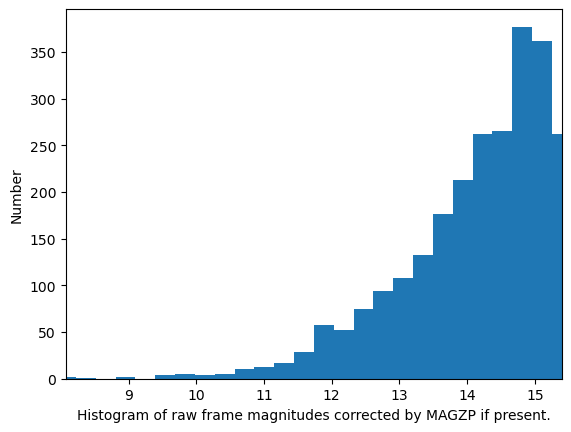

2024-10-30 16:47:32,073:INFO:check plots created. Saving figure...
2024-10-30 16:47:34,219:WARNING:Input data contains invalid values (NaNs or infs), which were automatically clipped.
2024-10-30 16:47:34,220:INFO:Filtering: number of data points 3661 ---> 2227
2024-10-30 16:47:34,236:INFO:create_ds9_reg_file: DS9 region file '/home/lceledon/Investigacion/OmegaCam/Work_dir//science/CP_Pup/Calibration_dir/CP_Pup_r_SDSS.coadd.reg' created successfully.
2024-10-30 16:47:34,240:INFO:create_ds9_reg_file: DS9 region file '/home/lceledon/Investigacion/OmegaCam/Work_dir//science/CP_Pup/Calibration_dir/CP_Pup_r_SDSS.coadd_filtered.reg' created successfully.
2024-10-30 16:47:34,261:WARNING:Input data contains invalid values (NaNs or infs), which were automatically clipped.
2024-10-30 16:47:34,263:INFO:Filtering: number of data points 3661 ---> 2099 (19099 19987)


Index(['x_all', 'y_all', 'mag_std', 'mag_frame', 'z_all', 'z_all_err'], dtype='object')


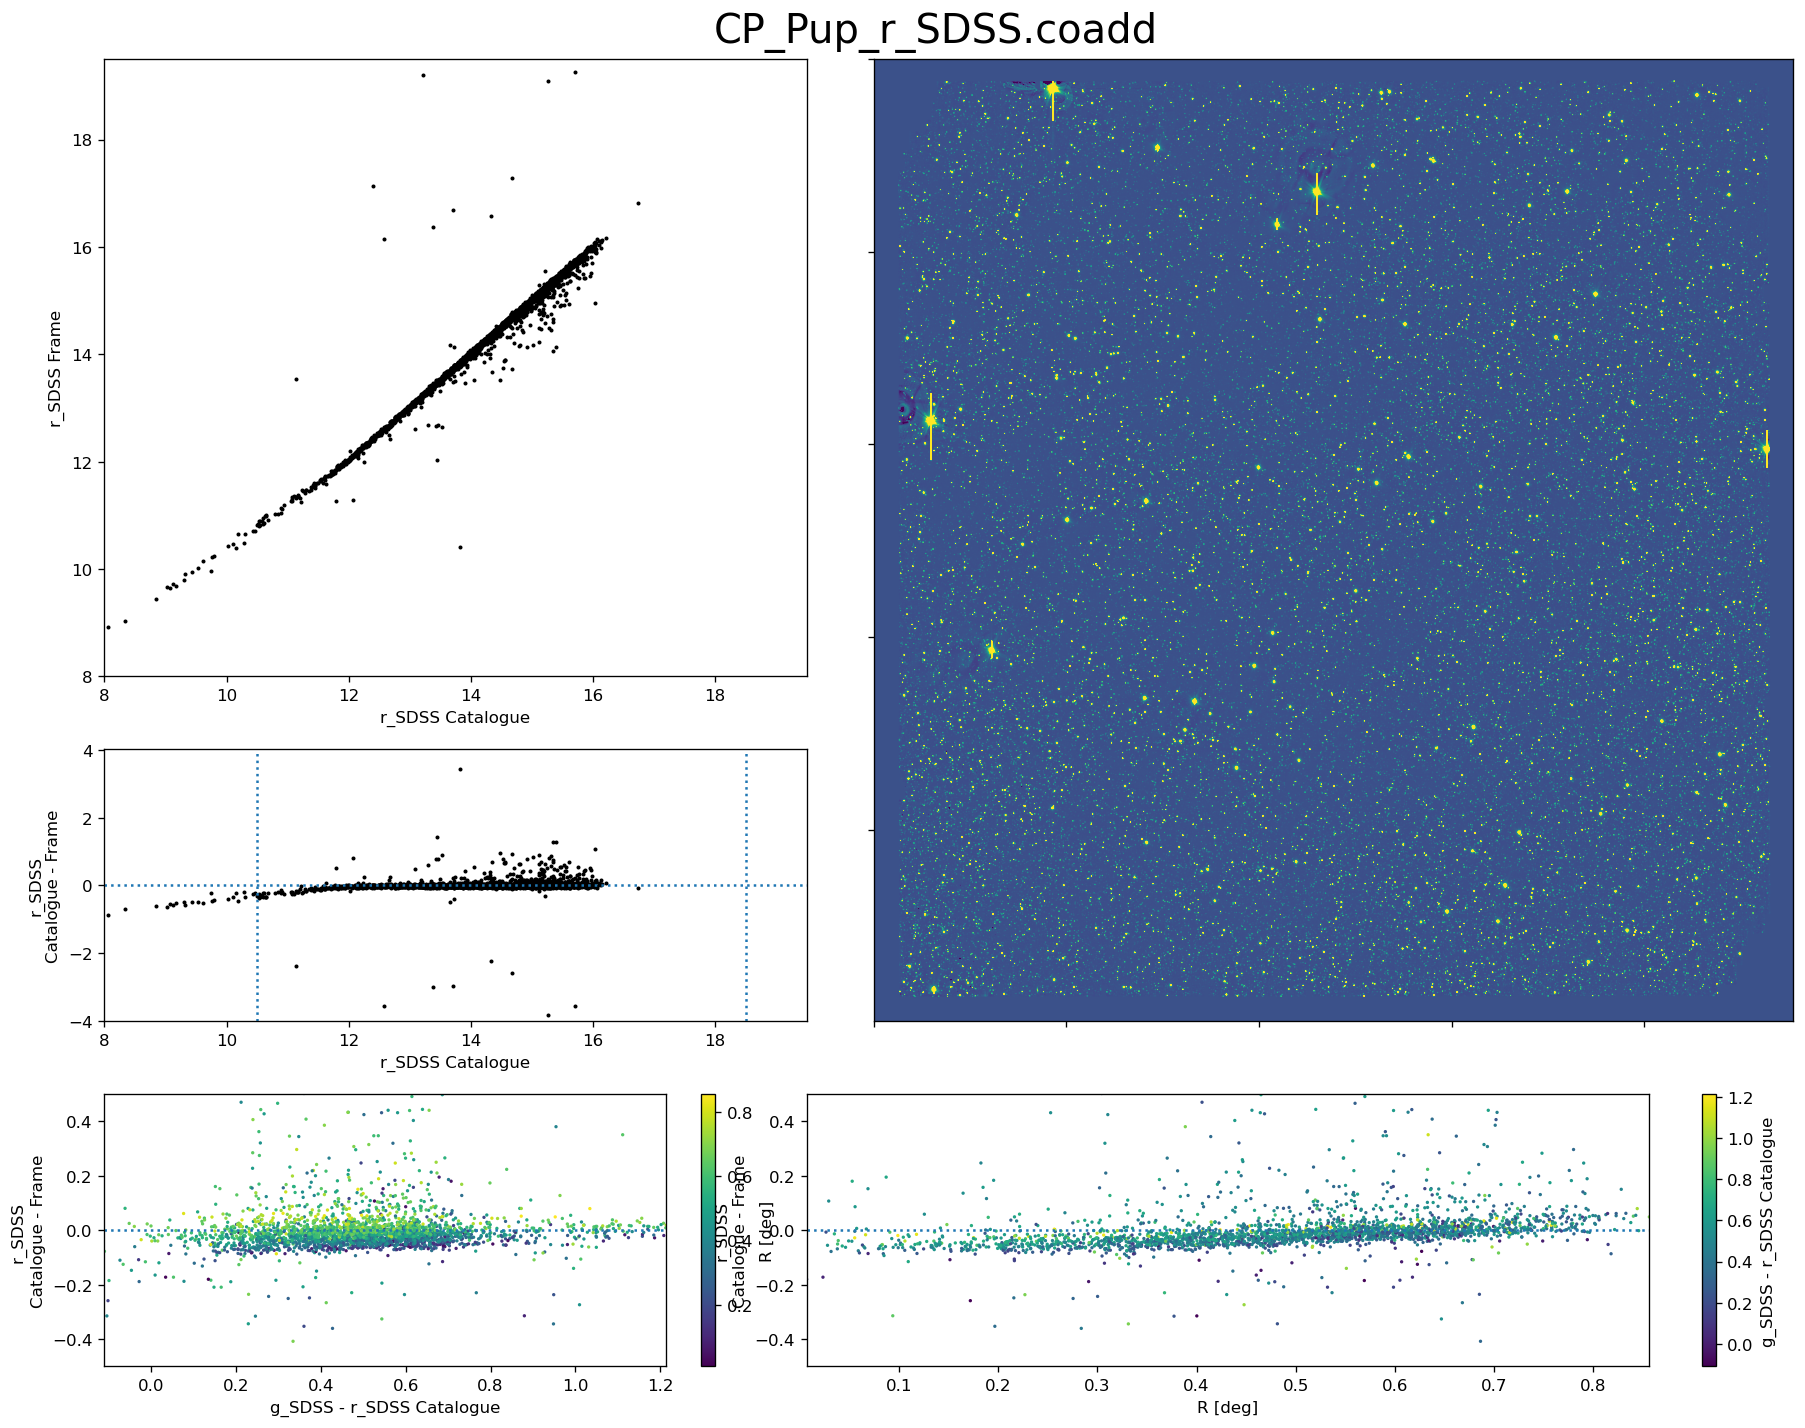

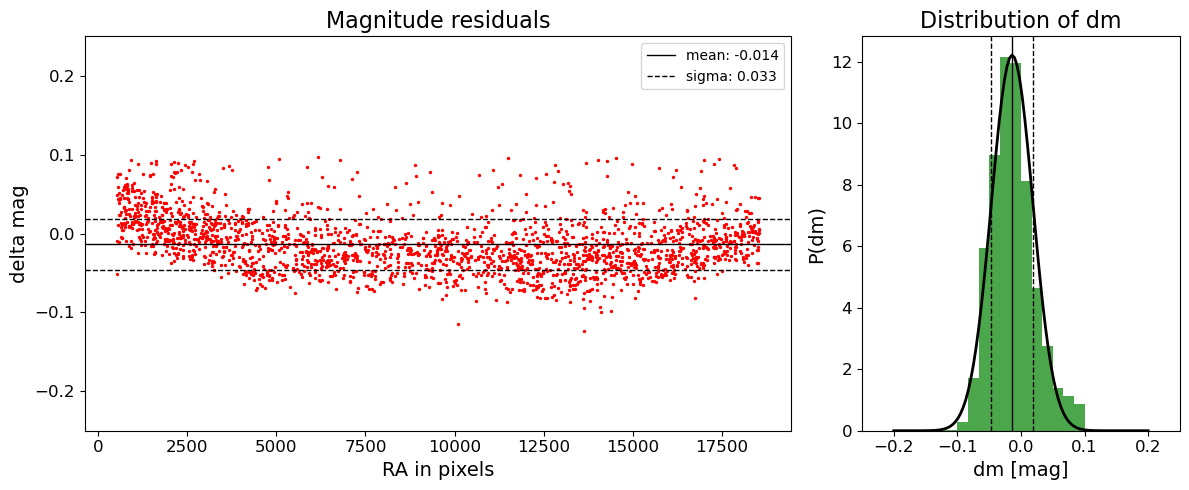

2024-10-30 16:47:36,052:INFO:-------Done-------


In [7]:
# Here we loop over the images selected
# See list above to select a data partition to calibrate
# For example, if the list is:
#
# index: 0 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/CP_Pup/Swarp_dir/CP_Pup_r_SDSS.coadd.fits
# index: 1 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/M67/Swarp_dir/M67_g_SDSS.coadd.fits
# index: 2 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/M67/Swarp_dir/M67_r_SDSS.coadd.fits
# index: 3 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/M67/Swarp_dir/M67_NB_659.coadd.fits
# index: 4 -- file: /Users/fselman/Pictures/OCAM/MultiObject/std/SA101/Swarp_dir/SA101_g_SDSS.coadd.fits
# index: 5 -- file: /Users/fselman/Pictures/OCAM/MultiObject/std/SA101/Swarp_dir/SA101_r_SDSS.coadd.fits
# index: 6 -- file: /Users/fselman/Pictures/OCAM/MultiObject/std/SA98/Swarp_dir/SA98_NB_659.coadd.fits
#
# then to calibrate M67_NB_659.coadd.fits set
#
# idx_selected = [3]
#

idx_selected = [1]    # Keep empty to check all files
for i in range(len(images_to_check)):
    
    # skip indices not in list idx_selected
    if not (i in idx_selected or not idx_selected):
        continue

    logging.info(f"calibrating image: {images_to_check[i]}")
    zpcal = extract_calibration(images_to_check[i])

    image_dir = os.path.dirname(zpcal.image_path)
    image_name = os.path.basename(zpcal.image_path)[:-5]     # Note that it assumes that we strip the fits extension
    image_path = image_dir+'/'+image_name
    

    plot_zpcal(zpcal, img_scaling=4)

    # we filter the data. This creates masked arrays for further use
    dm_min=-0.4
    dm_max=0.4
    brightest_mag=12.5
    faintest_mag=17.0
    zpcal.filter_data(dm_min=dm_min, dm_max=dm_max, brightest_mag=brightest_mag, faintest_mag=faintest_mag)

    n_before_filter = len(zpcal.x)
    n_after_filter = len(zpcal.x_masked)
    logging.info("Filtering: number of data points {} ---> {}".format(n_before_filter, n_after_filter))

    # We create a ds9 region file for inspection
    zpcal.create_ds9_region()

    # Here we save the data needed for illumination correction to a file.
    save_illumination_data(zpcal)

    # For checking we read it again and continue with plotting
    headers, data_df = read_illumination_data(image_path+'.illum.csv')
    #display(data_df)
    print(data_df.columns)

    x_all = data_df['x_all']
    y_all = data_df['y_all']
    z_all = data_df['z_all']
    z_all_err = data_df['z_all_err']
    mag_std = data_df['mag_std']

    dimx = int(headers['dimx'])
    dimy = int(headers['dimy'])
    origfile = headers['origfile']
    brightest_mag = 13.0
    faintest_mag = 17.0
    dm_min = -0.25
    dm_max = 0.25

    z_all_clipped = sigma_clip(z_all, sigma=3.0, maxiters=5)
    mask = ~np.isnan(z_all) & ~z_all_clipped.mask & np.isfinite(z_all) & \
        (brightest_mag < mag_std) & (mag_std < faintest_mag) & \
        (dm_min < z_all) & (z_all < dm_max)
    x_subset = x_all[mask]
    y_subset = y_all[mask]
    z_subset = z_all[mask]
    z_subset_err = z_all_err[mask]

    n_before_filter = len(x_all)
    n_after_filter = len(x_subset)
    logging.info("Filtering: number of data points {} ---> {} ({} {})".format(n_before_filter, n_after_filter, dimx, dimy))

    ############################ 03 PLOT RESIDUALS AND PDF FOR UNCORRECTED DATA ####################
    #
    plot_residuals(x_subset, z_subset, ylim=(-0.25, 0.25))
    
    logging.info("-------Done-------")

In [4]:
# Here we save the data needed for illumination correction to a file.
save_illumination_data(zpcal)


# For checking we read it again and continue with plotting
headers, data_df = read_illumination_data(image_path+'.illum.csv')
#display(data_df)
print(data_df.columns)

x_all = data_df['x_all']
y_all = data_df['y_all']
z_all = data_df['z_all']
z_all_err = data_df['z_all_err']
mag_std = data_df['mag_std']

dimx = int(headers['dimx'])
dimy = int(headers['dimy'])
origfile = headers['origfile']
brightest_mag = 13.0
faintest_mag = 17.0
dm_min = -0.25
dm_max = 0.25

z_all_clipped = sigma_clip(z_all, sigma=3.0, maxiters=5)
mask = ~np.isnan(z_all) & ~z_all_clipped.mask & np.isfinite(z_all) & \
        (brightest_mag < mag_std) & (mag_std < faintest_mag) & \
        (dm_min < z_all) & (z_all < dm_max)
x_subset = x_all[mask]
y_subset = y_all[mask]
z_subset = z_all[mask]
z_subset_err = z_all_err[mask]

n_before_filter = len(x_all)
n_after_filter = len(x_subset)
logging.info("Filtering: number of data points {} ---> {} ({} {})".format(n_before_filter, n_after_filter, dimx, dimy))

2024-10-30 16:46:54,960:WARNING:Input data contains invalid values (NaNs or infs), which were automatically clipped.
2024-10-30 16:46:54,963:INFO:Filtering: number of data points 3661 ---> 2132 (19119 19987)


Index(['x_all', 'y_all', 'mag_std', 'mag_frame', 'z_all', 'z_all_err'], dtype='object')


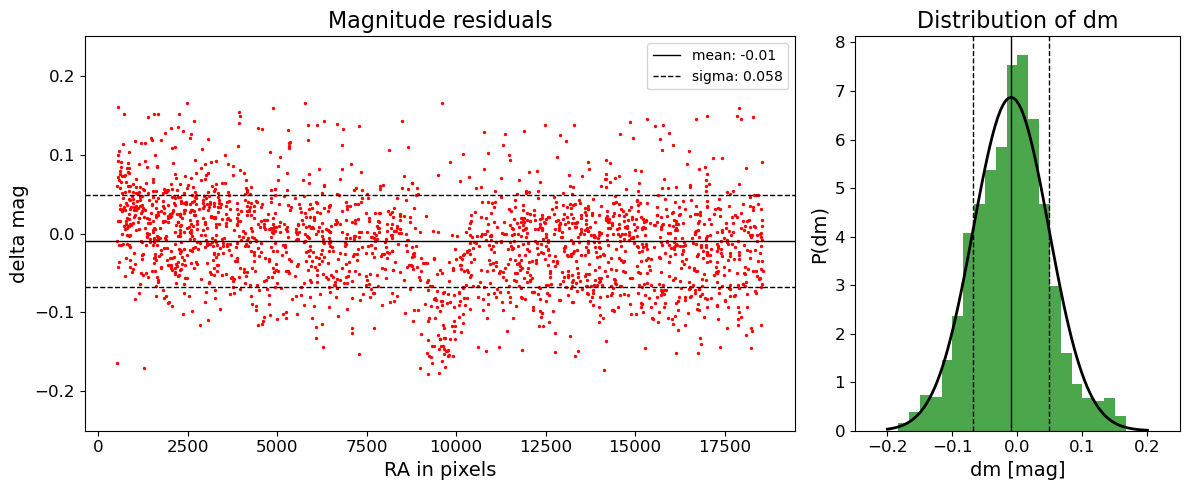

In [5]:
############################ 03 PLOT RESIDUALS AND PDF FOR UNCORRECTED DATA ####################
#
plot_residuals(x_subset, z_subset, ylim=(-0.25, 0.25))

### 